# Análisis ConnectaTel

Como **analista de datos**, tu objetivo es evaluar el **comportamiento de los clientes** de una empresa de telecomunicaciones en Latinoamérica, ConnectaTel. 

Trabajaremos con información registrada **hasta el año 2024**, lo cual permitirá analizar el comportamiento del negocio dentro de ese periodo.

Para ello trabajarás con tres datasets:  

- **plans.csv** → información de los planes actuales (precio, minutos incluidos, GB incluidos, costo por extra)  
- **users.csv** → información de los clientes (edad, ciudad, fecha de registro, plan, churn)  
- **usage.csv** → detalle del **uso real** de los servicios (llamadas y mensajes)  

Deberás **explorar**, **limpiar** y **analizar** estos datos para construir un **perfil estadístico** de los clientes, detectar **comportamientos atípicos** y crear **segmentos de clientes**.  

Este análisis te permitirá **identificar patrones de consumo**, **diseñar estrategias de retención** y **sugerir mejoras en los planes** ofrecidos por la empresa.

> 💡 Antes de empezar, recuerda pensar de forma **programática**: ¿qué pasos necesitas? ¿En qué orden? ¿Qué quieres medir y por qué?


--- 
## 🧩 Paso 1: Cargar y explorar

Antes de limpiar o combinar los datos, es necesario **familiarizarte con la estructura de los tres datasets**.  
En esta etapa, validarás que los archivos se carguen correctamente, conocerás sus columnas y tipos de datos, y detectarás posibles inconsistencias.

### 1.1 Carga de datos y vista rápida

**🎯 Objetivo:**  
Tener los **3 datasets listos en memoria**, entender su contenido y realizar una revisión preliminar.

**Instrucciones:**  
- Importa las librerías necesarias (por ejemplo `pandas`, `seaborn`, `matplotlib.pyplot`)
- Carga los archivos CSV usando `pd.read_csv()`:
  - **`/datasets/plans.csv`**  
  - **`/datasets/users_latam.csv`**  
  - **`/datasets/usage.csv`**  
- Guarda los DataFrames en las variables: `plans`, `users`, `usage`.  
- Muestra las primeras filas de cada DataFrame usando `.head()`.


In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
# cargar archivos
plans = pd.read_csv('/datasets/plans.csv')
users = pd.read_csv('/datasets/users_latam.csv')
usage = pd.read_csv('/datasets/usage.csv')

In [3]:
plans.head(5)

,plan_name,messages_included,gb_per_month,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute
0,Basico,100,5,100,12,1.2,0.08,0.10
1,Premium,500,20,600,25,1.0,0.05,0.07


In [4]:
users.head(5)

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date
0,10000,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN
1,10001,Mateo,Torres,53,?,2022-01-01 06:34:17.914478619,Basico,NaN
2,10002,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN
3,10003,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN
4,10004,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478,Basico,NaN


In [5]:
usage.head(5)

,id,user_id,type,date,duration,length
0,1,10332,call,2024-01-01 00:00:00.000000000,0.09,NaN
1,2,11458,text,2024-01-01 00:06:30.969774244,NaN,39.0
2,3,11777,text,2024-01-01 00:13:01.939548488,NaN,36.0
3,4,10682,call,2024-01-01 00:19:32.909322733,1.53,NaN
4,5,12742,call,2024-01-01 00:26:03.879096977,4.84,NaN


**Tip:** Si no usas `print()` la tabla se vera mejor.

### 1.2 Exploración de la estructura de los datasets

**🎯 Objetivo:**  
Conocer la **estructura de cada dataset**, revisar cuántas filas y columnas tienen, identificar los **tipos de datos** de cada columna y detectar posibles **inconsistencias o valores nulos** antes de iniciar el análisis.

**Instrucciones:**  
- Revisa el **número de filas y columnas** de cada dataset usando `.shape`.  
- Usa `.info()` en cada DataFrame para obtener un **resumen completo** de columnas, tipos de datos y valores no nulos.  

In [6]:
# revisar el número de filas y columnas de cada dataset
print("plans", plans.shape)
print("users", users.shape)
print("usage", usage.shape)

plans (2, 8)
users (4000, 8)
usage (40000, 6)


In [7]:
plans.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   plan_name          2 non-null      object 
 1   messages_included  2 non-null      int64  
 2   gb_per_month       2 non-null      int64  
 3   minutes_included   2 non-null      int64  
 4   usd_monthly_pay    2 non-null      int64  
 5   usd_per_gb         2 non-null      float64
 6   usd_per_message    2 non-null      float64
 7   usd_per_minute     2 non-null      float64
dtypes: float64(3), int64(4), object(1)
memory usage: 256.0+ bytes


In [8]:
users.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     4000 non-null   int64 
 1   first_name  4000 non-null   object
 2   last_name   4000 non-null   object
 3   age         4000 non-null   int64 
 4   city        3531 non-null   object
 5   reg_date    4000 non-null   object
 6   plan        4000 non-null   object
 7   churn_date  466 non-null    object
dtypes: int64(2), object(6)
memory usage: 250.1+ KB


In [9]:
usage.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        40000 non-null  int64  
 1   user_id   40000 non-null  int64  
 2   type      40000 non-null  object 
 3   date      39950 non-null  object 
 4   duration  17924 non-null  float64
 5   length    22104 non-null  float64
dtypes: float64(2), int64(2), object(2)
memory usage: 1.8+ MB


---

## 🧩Paso 2: Identificación de problemas de calidad de datos

### 2.1 Revisión de valores nulos

**🎯 Objetivo:**  
Detectar la presencia y magnitud de valores faltantes para evaluar si afectan el análisis o requieren imputación/eliminación.

**Instrucciones:**  
- Cuenta valores nulos por columna para cada dataset.
- Calcula la proporción de nulos por columna para cada dataset.

El dataset `plans` solamente tiene 2 renglones y se puede observar que no tiene ausentes, por ello no necesita exploración adicional.

<br>
<details>
<summary>Haz clic para ver la pista</summary>
Usa `.isna().sum()` para contar valores nulos y usa `.isna().mean()` para calcular la proporción.

In [10]:
# cantidad de nulos para users
print(users.isna().sum())# Cantidad de valores nulos)
print(users.isna().mean())# Proporción de valores nulos)

user_id          0
first_name       0
last_name        0
age              0
city           469
reg_date         0
plan             0
churn_date    3534
dtype: int64
user_id       0.00000
first_name    0.00000
last_name     0.00000
age           0.00000
city          0.11725
reg_date      0.00000
plan          0.00000
churn_date    0.88350
dtype: float64


In [11]:
print(usage.isna().sum())
print(usage.isna().mean())

id              0
user_id         0
type            0
date           50
duration    22076
length      17896
dtype: int64
id          0.00000
user_id     0.00000
type        0.00000
date        0.00125
duration    0.55190
length      0.44740
dtype: float64


✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico al final del bloque. Incluye qué ves y que acción recomendarías para cada caso.

💡 **Nota:** Justifica tus decisiones brevemente (1 línea por caso).
* Hint:
 - Si una columna tiene **más del 80–90% de nulos**, normalmente se **ignora o elimina**.  
 - Si tiene **entre 5% y 30%**, generalmente se **investiga para imputar o dejar como nulos**.  
 - Si es **menor al 5%**, suele ser un caso simple de imputación o dejar como nulos. 
 
 ---

**Valores nulos**  
- ¿Qué columnas tienen valores faltantes y en qué proporción?
   Para el dataset de users se observa que en la columna city tiene 469 valores faltantes, siendo un 11% de nulos y en la columna churn_date, tiene un alto porcentaje de ausencia con un 88%
  para el data set de usage tiene una proporcion de 55% en la columna duration y 44% en lenth
- Indica qué harías: ¿imputar, eliminar, ignorar?

  para el caso de users en la columna de city se investigara para imputar o dejar nulos, y en la columna churn_date, se eliminaran o se ignorara

  En el dataset de usage, se observan dos columnas con 55% y 44% de nulos se ignoraran o elimanaran

### 2.2 Detección de valores inválidos y sentinels

🎯 **Objetivo:**  
Identificar sentinels: valores que no deberían estar en el dataset.

**Instrucciones:**
- Explora las columnas numéricas con **un resumen estadístico** y describe brevemente que encontraste.
- Explora las columnas categóricas **relevantes**, revisando sus valores únicos y describe brevemente que encontraste.


El dataset `plans` solamente tiene 2 renglones, por ello no necesita exploración adicional.

- La columna `user_id` se observa datos completos, sin ausentes 40000 de 40000
- La columna `age` En esta columna tambien los datos estan completos sin ausentes, pero se necesita correcion ya que hay errores de datos en 56 filas con '-999'

In [12]:
# explorar columnas numéricas de usage

- Las columnas `id` y `user_id` no se encontraron errores que podrian alterar los datos o cambiar promedios, y sin datos ausentes

In [13]:
# explorar columnas categóricas de users
columnas_user = ['city', 'plan']



- La columna `city` En la columna de archivo users, se debe corregir y arreglar varias filas con ausentes y con '?' un promedio de 11%
- La columna `plan` En la columna solo se aprecia planes basicos y premium, los datos estan completos en la columna

In [14]:
# explorar columna categórica de usage
usage['type'].describe() # completa el código

count     40000
unique        2
top        text
freq      22092
Name: type, dtype: object

- La columna `type` revisando la columna del archivo usage, tenemos los datos completos, solo hay dos filas ausentes, sin comprometer el data


---
✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico. Incluye qué ves y que acción recomendarías para cada caso. 

**Valores inválidos o sentinels**  
- ¿En qué columnas encontraste valores inválidos o sentinels?
   encontre valores invalidos del archivo de users columna 'age' con errores como -999 sin ausentes, en la columna 'city' 469 datos ausentes, o desconocidos, 11% ausencia, y la columna 'churn_Date', casi la totalidad no hay datos un 88% de ausencia
  En el archivo de usage, las columnas 'duration' y 'lenght' no hay regsitros de datos un 55% de ausencia en 'duration' y un 44% en 'length'
  En la columna 'date' del archivo users, lo cambiaria a archivo tipo fecha UTC
- ¿Qué acción tomarías?
- para el archivo de users en las columnas con mayor ausencia de datos, se ignoraran o se eliminaran, como en la columna de 'churn_date', en el caso de la columna 'age' ya que es mas relevante, se investigara para imputar o dejar como nulos

### 2.3 Revisión y estandarización de fechas

**🎯 Objetivo:**  
Asegurar que las columnas de fecha estén correctamente formateadas y detectar años fuera de rango que indiquen errores de captura.

**Instrucciones:**  
- Convierte las columnas de fecha a tipo fecha y asegurate de que el código sea a prueba de errores.  
- Revisa cuántas veces aparece cada año.
- Identifica fechas imposibles (ej. años futuros o negativos).

Toma en cuenta que tenemos datos registrados hasta el año 2024.

In [15]:
# Convertir a fecha la columna `reg_date` de users
users['reg_date'] = pd.to_datetime(users['reg_date'], errors='coerce', utc=True)

In [16]:
# Convertir a fecha la columna `date` de usage
usage['date'] = pd.to_datetime(usage['date'], errors='coerce', utc=True)

In [17]:
# Revisar los años presentes en `reg_date` de users
users['reg_date'].dt.year.unique()

array([2022, 2026, 2023, 2024])

En `reg_date`, array solo se observan los años 2022, 2023, 2024, no hay mas registros de años

In [18]:
# Revisar los años presentes en `date` de usage
usage['date'].dt.year.unique()

array([2024.,   nan])

En `date`, solo tenemos 2024, y nan datos faltantes en el dataset  
Basaremos el análisis en estas fechas.

✍️ **Comentario**: escribe tu diagnóstico, e incluye **qué acción recomendarías** para cada caso:

**Fechas fuera de rango**  
- ¿Aparecen años imposibles? (años muy viejos o sin transcurrir al momento de guardar los datos)
- aparecen fechas imposibles pero no viejos si no futuros, como 2026, y el archivo va hasta 2024, por lo tanto es una fecha imposible
- ¿Qué harías con ellas?
- para las fechas fuera de linea de tiempo lo eliminaria o lo ingoraria ya que no tiene relevancia en la investigacion 

---

## 🧩Paso 3: Limpieza básica de datos

### 3.1 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Aplicar reglas de limpieza para reemplazar valores sentinels y corregir fechas imposibles.

**Instrucciones:**  
- En `age`, reemplaza el sentinel **-999** con la mediana.
- En `city`, reemplaza el sentinel `"?"` por valores nulos (`pd.NA`).  
- Marca como nulas (`pd.NA`) las fechas fuera de rango.

In [19]:
# Reemplazar -999 por la mediana de age
age_mediana = users[users['age'] != -999]['age'].median()
users['age'] = users['age'].where(users['age'] != -999, age_mediana)

users['age'].describe()

count    4000.000000
mean       48.136000
std        17.689919
min        18.000000
25%        33.000000
50%        48.000000
75%        63.000000
max        79.000000
Name: age, dtype: float64

In [20]:
# Reemplazar ? por NA en city
users['city'] = users['city'].where(users['city'] != '?', pd.NA)

# Verificar cambios
users['city'].describe()

count       3435
unique         6
top       Bogotá
freq         808
Name: city, dtype: object

In [21]:
# Marcar fechas futuras como NA para reg_date
users['reg_date'] = (users['reg_date'].where((users['reg_date']>= '2022-01-01') & (users['reg_date'] <= '2024-12-31'), pd.NA))

# Verificar cambios
users['reg_date'].describe()

count                                    3960
unique                                   3960
top       2023-12-20 18:33:45.506376600+00:00
freq                                        1
first               2022-01-01 00:00:00+00:00
last                2024-12-31 00:00:00+00:00
Name: reg_date, dtype: object

### 3.2 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Decidir qué hacer con los valores nulos según su proporción y relevancia.

**Instrucciones:**
- Verifica si los nulos en `duration` y `length` son **MAR**(Missing At Random) revisando si dependen de la columna `type`.  
  Si confirmas que son MAR, **déjalos como nulos** y justifica la decisión.

In [22]:
# Verificación MAR en usage (Missing At Random) para duration
usage['duration_missing_flag'] = usage['duration'].isna().astype(int)
usage.groupby('type')['duration_missing_flag'].mean()

type
call    0.000000
text    0.999276
Name: duration_missing_flag, dtype: float64

In [23]:
# Verificación MAR en usage (Missing At Random) para length
usage['length_missing_flag'] = usage['length'].isna().astype(int)
usage.groupby('type')['length_missing_flag'].mean()

type
call    0.99933
text    0.00000
Name: length_missing_flag, dtype: float64

`duration` y `length` en las columnas faltan datos mas del 99% , pero no son missin at random (MAR), en realidad son faltantes por diseño, ya que en 'duration' los mensajes de texto no existen ya que son llamadas, y en 'length' existe los datos de texto o longitud de texto, pero no tiene duracion ya que son mensajes de texto

---

## 🧩Paso 4: Summary statistics de uso por usuario


### 4.1 Agrupación por comportamiento de uso

🎯**Objetivo**: Resumir las variables clave de la tabla `usage` **por usuario**, creando métricas que representen su comportamiento real de uso histórico. 

**Instrucciones:**: 
1. Construye una tabla agregada de `usage` por `user_id` que incluya:
- número total de mensajes  
- número total de llamadas  
- total de minutos de llamadas

2. Renombra las columnas para que tengan nombres claros:  
- `cant_mensajes`  
- `cant_llamadas`  
- `cant_minutos_llamada`
3. Combina esta tabla con `users`.

In [24]:
# Columnas auxiliares
usage["is_text"] = (usage["type"] == "text").astype(int) #conocer el total de mensajes
usage["is_call"] = (usage["type"] == "call").astype(int) #conocer el total de llamadas


# Agrupar información por usuario
usage_men = usage.groupby('user_id')['length'].count().reset_index()
usage_agg = usage.groupby(['user_id', 'type'])['duration'].count().reset_index()
usage_cant = usage.groupby('user_id')['duration'].sum().reset_index()
# observar resultado
usage_agg.head(3)

,user_id,type,duration
0,10000,call,3
1,10000,text,0
2,10001,call,10


In [25]:
# Renombrar columnas

usage_agg = usage_agg.rename(columns={'duration': 'cant_llamadas'})
usage_cant = usage_cant.rename(columns={'duration': 'cant_minutos_llamada'})
usage_men = usage_men.rename(columns={'length': 'cant_mensajes'})
# observar resultado
usage_agg.head(3)


,user_id,type,cant_llamadas
0,10000,call,3
1,10000,text,0
2,10001,call,10


In [26]:
# Combinar la tabla agregada con el dataset de usuarios
user_profile = pd.merge(users, usage_agg, on=['user_id'], how='left')
user_profile = pd.merge(user_profile, usage_cant, on=['user_id'], how='left')
user_profile = pd.merge(user_profile, usage_men, on=['user_id'], how='left')
user_profile.head(5)
user_profile.shape

(7940, 12)

### 4.2 4.2 Resumen estadístico por usuario durante el 2024

🎯 **Objetivo:** Analizar las columnas numéricas y categóricas de los usuarios, para identificar rangos, valores extremos y distribución de los datos antes de continuar con el análisis.

**Instrucciones:**  
1. Para las columnas **numéricas** relevantes, obtén un resumen estadístico (media, mediana, mínimo, máximo, etc.).  
2. Para la columna **categórica** `plan`, revisa la distribución en **porcentajes** de cada categoría.

In [27]:
users.describe()


,user_id,age
count,4000.000000,4000.000000
mean,11999.500000,48.136000
std,1154.844867,17.689919
min,10000.000000,18.000000
25%,10999.750000,33.000000
50%,11999.500000,48.000000
75%,12999.250000,63.000000
max,13999.000000,79.000000


In [28]:
# Distribución porcentual del tipo de plan
columna_porcentual = users['plan']

print(columna_porcentual.value_counts(normalize=True) * 100)

Basico     64.875
Premium    35.125
Name: plan, dtype: float64


---

## 🧩Paso 5: Visualización de distribuciones (uso y clientes) y outliers


### 5.1 Visualización de Distribuciones

🎯 **Objetivo:**  
Entender visualmente cómo se comportan las variables clave tanto de **uso** como de **clientes**, observar si existen diferencias según el tipo de plan, y analizar la **forma de la distribución**.

**Instrucciones:**  
Graficar **histogramas** para las siguientes columnas:  
- `age` (edad de los usuarios)
- `cant_mensajes`
- `cant_llamadas`
- `total_minutos_llamada` 

Después de cada gráfico, escribe un **insight** respecto al plan y la variable, por ejemplo:  
- "Dentro del plan Premium, hay mayor proporción de..."  
- "Los usuarios Básico tienden a hacer ... llamadas y enviar ... mensajes."  o "No existe algún patrón."
- ¿Qué tipo de distribución tiene ? (simétrica, sesgada a la derecha o a la izquierda) 

**Hint**  
Para cada histograma, 
- Usa `hue='plan'` para ver cómo varían las distribuciones según el plan (Básico o Premium).
- Usa `palette=['skyblue','green']`
- Agrega título y etiquetas

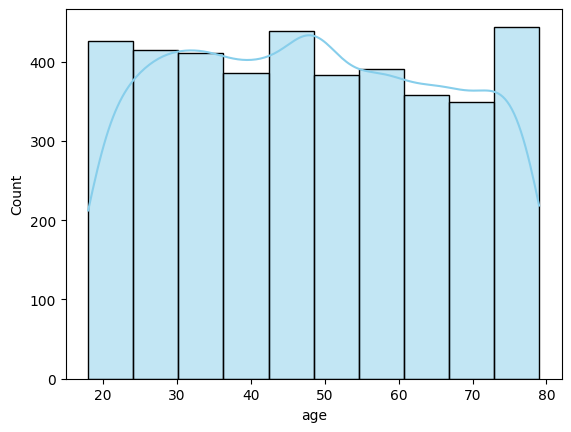

In [29]:
# Histograma para visualizar la edad (age)
sns.histplot(users['age'], bins=10, color='skyblue', kde=True)
plt.show()

💡Insights: 
- El histograma muestra que las edades de los usuarios se distribuyen de manera realtivamente uniforme entre los 18 y 80, sin una concentracion claramente dominante en un unico grupo de edad, no se observa asimetria marcada ni una concentracion evidente en edades especificas.

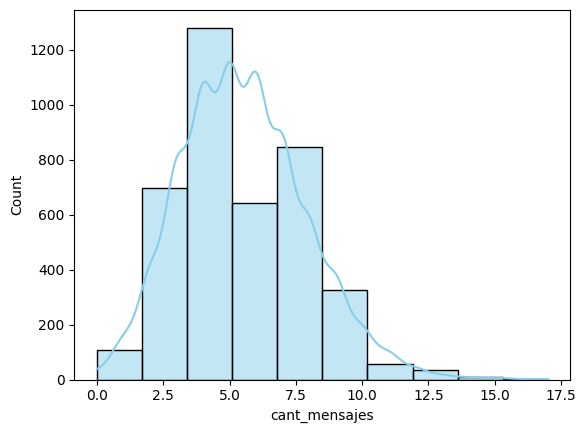

In [30]:
# Histograma para visualizar la cant_mensajes
sns.histplot(usage_men['cant_mensajes'], bins=10, color='skyblue', kde=True)
plt.show()

💡Insights: 
- En el histograman se observa sesgo a la derecha, indicando  que la mayoria de los usuarios envia aproximadamente entre 3 y 8 mensajes, con una mayor concentracion alrededor de 4 a 6 mensajes. La distribucion no es simetrica y podria presentar  valores extremos en el rango superior ya que el sesgo a la derecha podria elevar la media.

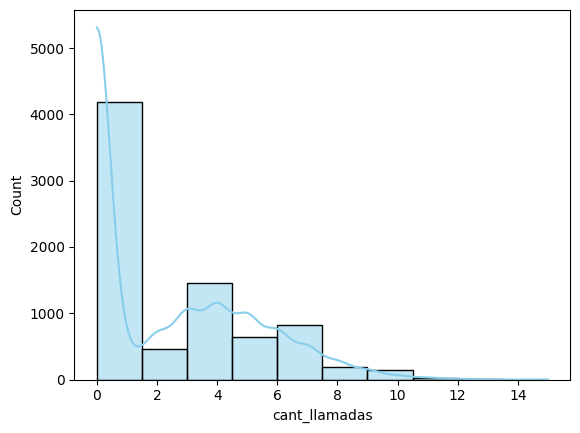

In [31]:
# Histograma para visualizar la cant_llamadas
sns.histplot(usage_agg['cant_llamadas'], bins=10, color='skyblue', kde=True)
plt.show()

💡Insights: 
- la cantidad de llamadas presenta una distribucion asimetrica positiva, concentrandose en la mayoria de los registros en valores bajos, especialmente alrededor de 0 - 11 llamadas. la frecuencia disminuye, aunque existen algunos grupos de clientes con un mayor numero de llamadas.

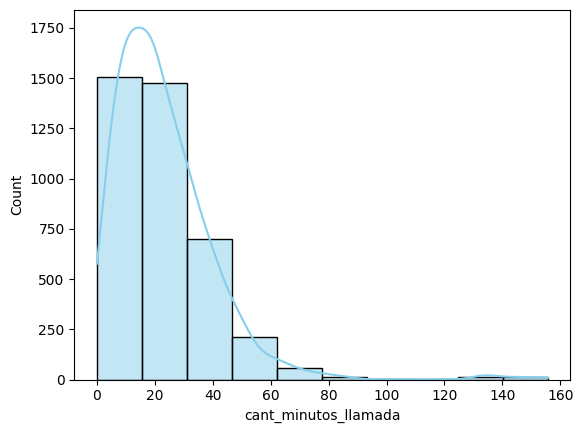

In [32]:
# Histograma para visualizar la cant_minutos_llamada
sns.histplot(usage_cant['cant_minutos_llamada'], bins=10, color='skyblue', kde=True)
plt.show()

💡Insights: 
La duracion de las llamadas presenta una distribucion asimetrica postiva, concentrandose principalmente en llamadas de corta duracion entre 0 y 30 minutos, a medida que aumenta la duracion la frecuencia disminuye considerablemente, aunque con casos q superan los 100 mminutoswss

### 5.2 Identificación de Outliers

🎯 **Objetivo:**  
Detectar valores extremos en las variables clave de **uso** y **clientes** que podrían afectar el análisis, y decidir si requieren limpieza o revisión adicional.

**Instrucciones:**  
- Usa **boxplots** para identificar visualmente outliers en las siguientes columnas:  
  - `age` 
  - `cant_mensajes`
  - `cant_llamadas`
  - `total_minutos_llamada`  
- Crea un **for** para generar los 4 boxplots automáticamente.
<br>

- Después de crear los gráfico, responde si **existen o no outliers** en las variables.  
- Si hay outliers, crea otro bucle para calcular los límites de esas columnas usando el **método IQR** y decide qué hacer con ellos.
  - Si solamente hay outliers de un solo lado, no es necesario calcular ambos límites.

**Hint:**
- Dentro del bucle, usa `plt.title(f'Boxplot: {col}')` para que el título cambie acorde a la columna.

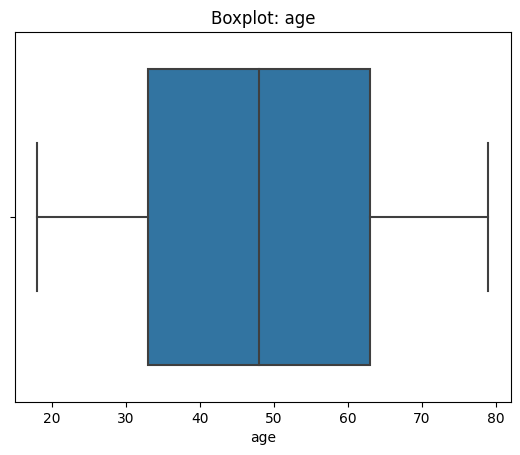

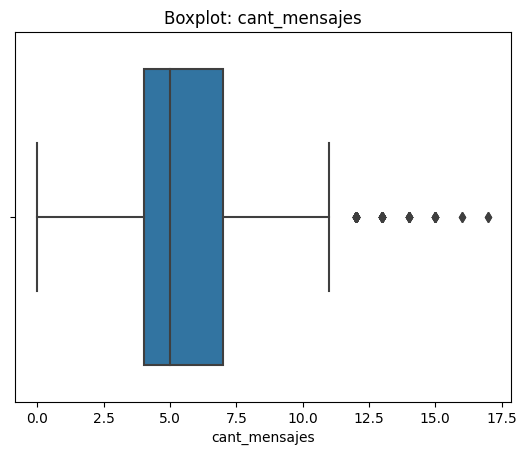

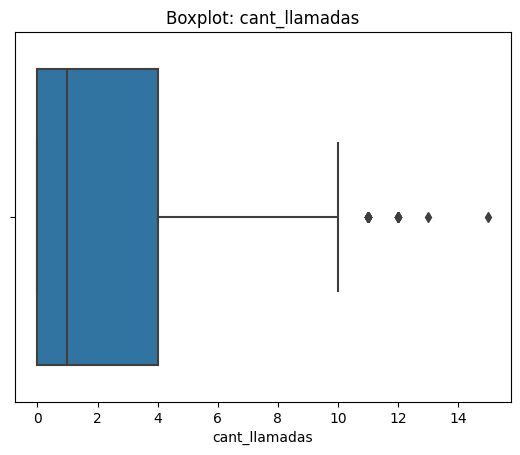

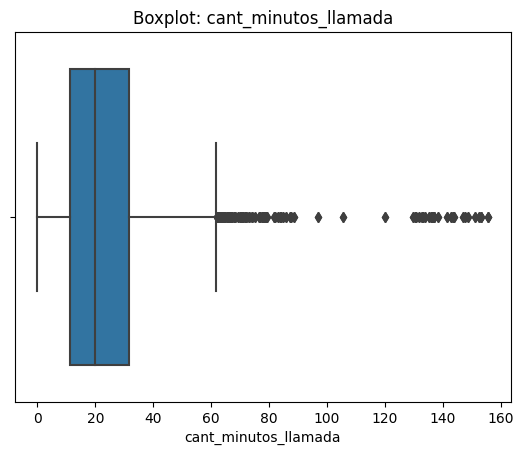

In [33]:
# Visualizando usando BoxPlot 

columnas_numericas = ['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']


for col in columnas_numericas:
    sns.boxplot(data=user_profile, x=col)
    plt.title(f'Boxplot: {col}')
    plt.show()



💡Insights: 
- Age: En la grafica se muestra un balance sin datos fuera de rango o desproporcionado, no presenta outliars
- cant_mensajes: se muestra en la grafica un sesgo hacia la derecha superando el cuartil superior Q3. mostrando valores atipicos
- cant_llamadas: presenta sesgo a la derecha, con valores atipicos
- cant_minutos_llamada:la grafica presenta un promedio entre 0 a 20 minutos por llamda, con cuartil superior de hasta 60 minutos, tambien se observan varios valores atipicos, llegando a registrar llamadas de mas de 100 minutos

In [34]:
# Calcular límites con el método IQR
columnas_limites = []

for col in columnas_numericas:
    q1 = user_profile[col].quantile(0.25)
    q2 = user_profile[col].quantile(0.50)
    q3 = user_profile[col].quantile(0.75)
    iqr = q3 - q1
    limite_inferior = q1 - 1.5 * iqr
    limite_superior = q3 + 1.5 * iqr
    columnas_limites.append((col, limite_inferior, limite_superior))



In [35]:
# Revisa los limites superiores y el max, para tomar la decisión de mantener los outliers o no
user_profile[columnas_numericas].describe()

,age,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,7940.000000,7939.00000,7939.000000,7939.000000
mean,48.128212,5.54037,2.257715,23.404688
std,17.690419,2.34625,2.705982,18.076776
min,18.000000,0.00000,0.000000,0.000000
25%,33.000000,4.00000,0.000000,11.260000
50%,48.000000,5.00000,1.000000,19.840000
75%,63.000000,7.00000,4.000000,31.490000
max,79.000000,17.00000,15.000000,155.690000


💡Insights: 
- cant_mensajes: mantener o no outliers, porqué?
  se muestra en Q3 = 75% 17 mensajes, lo mantendria, aunque es un valor estadisticamente arriba del limite superior, pienso q 17 mesnajes es un comportamiento normal y realista, eliminar estos datos significaria ignorar a los usuarios mas activos o heavy users, lo cual cambiaria el analisis comercial.
- cant_llamadas: mantener o no outliers, porqué?
   Q3 = 75% entre 4 llamadas maximo 15 llamadas, lo mantendria porque un maximo de 15 llamadas en el periodo registrado es una cifra factible carcana a la realidad, en especial si se utiliza el servicio para trabajo, ventas o atencion al cliente.
- cant_minutos_llamada: mantener o no outliers, porqué?
  en el Q3 = 75% son 31 minutis y un maximo de 155 minutos, alrededor de 2.5 horas no es un outlier fuera de logica estadisticas, en la vida real es posible tener llamadas largas(conferencias o llamadas personales extensas). al no ser un nunero elevado o imposible como 5.000 minutos en un dia, representa el comportamiento real extremo de la poblacion

---

## 🧩Paso 6: Segmentación de Clientes

### 6.1 Segmentación de Clientes Por Uso

🎯 **Objetivo:** Clasificar a cada usuario en un grupo de uso (Bajo uso, Uso medio, Alto uso) basándose en la cantidad de llamadas y mensajes registrados.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_uso` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones de llamadas y mensajes y asigna:
  - `'Bajo uso'` cuando llamadas < 5 y mensajes < 5
  - `'Uso medio'` cuando llamadas < 10 y mensajes < 10
  - `'Alto uso'` para el resto de casos

In [36]:
# Crear columna grupo_uso
def llamada(row):
    men = row['cant_mensajes']
    lla = row['cant_llamadas']

    if men < 5 and  lla < 5:
         return 'Bajo uso'
    elif men < 10 and lla < 10:
         return 'Uso medio'
    else:
        return 'Alto uso'

user_profile['grupo_uso']=user_profile.apply(llamada, axis=1)

        
        

    

In [37]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,type,cant_llamadas,cant_minutos_llamada,cant_mensajes,grupo_uso
0,10000,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00+00:00,Basico,NaN,call,3.0,23.70,7.0,Uso medio
1,10000,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00+00:00,Basico,NaN,text,0.0,23.70,7.0,Uso medio
2,10001,Mateo,Torres,53,<NA>,2022-01-01 06:34:17.914478619+00:00,Basico,NaN,call,10.0,33.18,5.0,Alto uso
3,10001,Mateo,Torres,53,<NA>,2022-01-01 06:34:17.914478619+00:00,Basico,NaN,text,0.0,33.18,5.0,Uso medio
4,10002,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239+00:00,Basico,NaN,call,2.0,10.74,5.0,Uso medio


### 6.2 Segmentación de Clientes Por Edad

🎯 **Objetivo:**: Clasificar a cada usuario en un grupo por **edad**.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_edad` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones y asigna:
  - `'Joven'` cuando age < 30
  - `'Adulto'` cuando age < 60
  - `'Adulto Mayor'` para el resto de casos

In [38]:
# Crear columna grupo_edad
def edades(row):
    birth = row['age']

    if birth < 30: 
       return 'joven'
    elif birth < 60: 
       return 'Adulto'
    else:
      return 'Adulto Mayor'

user_profile['grupo_edad'] = user_profile.apply(edades, axis=1)
    

In [42]:
# verificar cambios
user_profile.head(10)

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,type,cant_llamadas,cant_minutos_llamada,cant_mensajes,grupo_uso,grupo_edad
0,10000,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00+00:00,Basico,NaN,call,3.0,23.70,7.0,Uso medio,Adulto
1,10000,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00+00:00,Basico,NaN,text,0.0,23.70,7.0,Uso medio,Adulto
2,10001,Mateo,Torres,53,<NA>,2022-01-01 06:34:17.914478619+00:00,Basico,NaN,call,10.0,33.18,5.0,Alto uso,Adulto
3,10001,Mateo,Torres,53,<NA>,2022-01-01 06:34:17.914478619+00:00,Basico,NaN,text,0.0,33.18,5.0,Uso medio,Adulto
4,10002,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239+00:00,Basico,NaN,call,2.0,10.74,5.0,Uso medio,Adulto
5,10002,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239+00:00,Basico,NaN,text,0.0,10.74,5.0,Uso medio,Adulto
6,10003,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858+00:00,Premium,NaN,call,3.0,8.99,11.0,Alto uso,Adulto Mayor
7,10003,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858+00:00,Premium,NaN,text,0.0,8.99,11.0,Alto uso,Adulto Mayor
8,10004,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478+00:00,Basico,NaN,call,3.0,8.01,4.0,Bajo uso,Adulto Mayor
9,10004,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478+00:00,Basico,NaN,text,0.0,8.01,4.0,Bajo uso,Adulto Mayor


### 6.3 Visualización de la Segmentación de Clientes

🎯 **Objetivo:** Visualizar la distribución de los usuarios según los grupos creados: **grupo_uso** y **grupo_edad**.

**Instrucciones:**  
- Crea dos gráficos para las variables categóricas `grupo_uso` y `grupo_edad`.
- Agrega título y etiquetas a los ejes en cada gráfico.

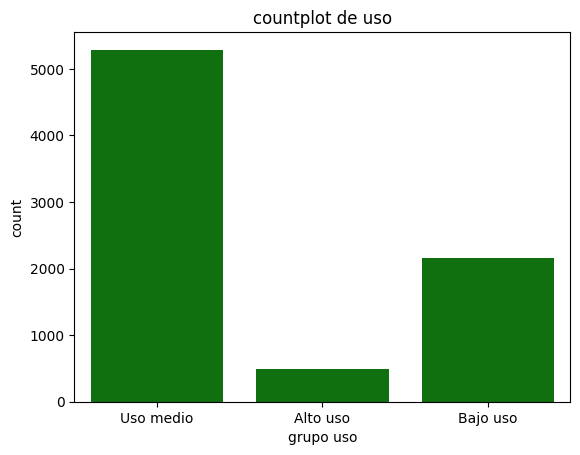

In [40]:
# Visualización de los segmentos por uso
sns.countplot(x=user_profile['grupo_uso'], color='green')
plt.title('countplot de uso')
plt.xlabel('grupo uso')

plt.show()

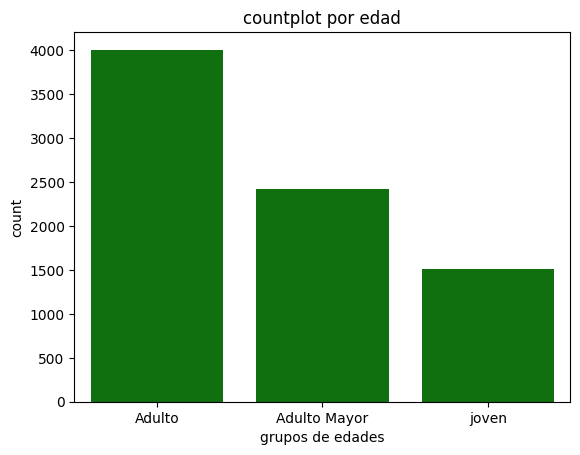

In [41]:
# Visualización de los segmentos por edad

sns.countplot(x=user_profile['grupo_edad'], color='green')
plt.title('countplot por edad')
plt.xlabel('grupos de edades')
plt.show()



---
## 🧩Paso 7: Insight Ejecutivo para Stakeholders

🎯 **Objetivo:** Traducir los hallazgos del análisis en conclusiones accionables para el negocio, enfocadas en segmentación, patrones de uso y oportunidades comerciales.

**Preguntas a responder:** 
- ¿Qué problemas tenían originalmemte los datos?¿Qué porcentaje, o cantidad de filas, de esa columna representaban?
bueno al inicar el proyecto, y consultando en la tabla users en primera observacion se vieron datos ausentes en date, duration, y legnth, pero que al final solo eran missing disign , por parte de las columnas 'duration' y 'length', en la columna de 'date' tenia el 5% de ausencia , muy bajo para alterar los datos, en la columna 'age' se reemplazaron errores  como -999 por pd.NA

Por la tabla de usage se muestran errores en datos en la columna 'city' errores como ausencia y el porcentaje era de un 11% por lo tanto no se ignoraron, y se reemplazaron por pd.NA, en la columna 'churn_date' faltaban casi en su totalidad un 88% de los datos, por lo tanto se ingnoraron


- ¿Qué segmentos de clientes identificaste y cómo se comportan según su edad y nivel de uso?
   se logra apreciar varios segmentos de clientes, jovenes, adultos, y mayores, en el uso de llamadas y mensajes, los adultos tiene un mayor uso que los jovenes y adultos mayores, tambien se logra evidenciar planes basicos y planes premium, siendo al gran mayoria usando planes basicos, pero sin dejar atras los planes premium
  
- ¿Qué segmentos parecen más valiosos para ConnectaTel y por qué?
   centrarse en atraer mas jovenes, ya que son los de menor participacion,
- ¿Qué patrones de uso extremo (outliers) encontraste y qué implican para el negocio?
observando los boxplot como se menciono anteriormente, son datos que podrian ocurrir en la vida real, como en cantidad de minutos, el dato mas alejado de Q3 era un promedio de 40 minutos, y el mas alejado es de 2.5 horas ya sea por llamadas personales externas o reuniones por llamadas, pero no es un dato imposible como de 1000 minutos o datos inflados, alejados de la realidad, deberian tener en cuenta sin ingorar los datos alejados de la media, ya que son heavyusers, postivo para el negocio

- ¿Qué recomendaciones harías para mejorar la oferta actual de planes o crear nuevos planes basados en los segmentos y patrones detectados?
recomendaria, crear un nuevo plan entre basico y premium, dando mas variedad a los usuarios, tanto adultos como jovenes, buscar la manera de atraer mas jovenes con el nuevo plan, ya que este segmento de edad esta bajo, el mercado aumentaria junto con los usuarios, con precios balanceados como un plan medio.
  

✍️ **Escribe aquí tu análisis ejecutivo:**

### Análisis ejecutivo

⚠️ **Problemas detectados en los datos**
- En el dataframe users se encontraron filas ausentes en la columna 'date' un 1%, en las columnas 'duration'y 'length' no tiene errores ni ausentes, ya que estaban diseñados de esa manera, tambien llamado missing disign.
- En usage, se encontraron datos ausentes en la columna 'city' se reemplazo por NA, y en la columna 'age' tenian algunas edades imposibles como -999, se reemplazo por pd.NA


🔍 **Segmentos por Edad**
- se observa una mayor cantidad de adultos en los archivos
- jovenes son los de menor cantidad posiblemente no hay variedad de planes y un menor flujo de este tipo de usuarios
- adultos mayores, con una cantidad moderada despues de los adultos



📊 **Segmentos por Nivel de Uso**
- En los niveles de uso entre planes basicos y planes premium, en el segmentos de usos se evidencia mayormente de un uso medio entre llamdas y mensajes, un alto uso es de la mas baja del histograma, y bajo uso esta con un alcance moderado


➡️ Esto sugiere que los usuarios mantenienen un uso mediano, los usuarios no tiene un uso habitual o prolongado, dando como resultado el alto uso en  una estadistica muy baja, recomendaria adicionar un plan que sea llamativo para la variedad de usuarios


💡 **Recomendaciones**
- se recomienda adicional opciones para los usarios, con otro tipo plan, y precio, llamanda a usuarios al mercado y dando mas variedad de planes, ya que el uso se mantiene entre bajo y medio
  

---

## 🧩Paso 8 Cargar tu notebook y README a GitHub

🎯 **Objetivo:**  
Entregar tu análisis de forma **profesional**, **documentada** y **versionada**, asegurando que cualquier persona pueda revisar, ejecutar y entender tu trabajo.



### Opción A : Subir archivos desde la interfaz de GitHub (UI)

1. Descarga este notebook (`File → Download .ipynb`).  
2. Entra a tu repositorio en GitHub (por ejemplo `telecom-analysis` o `sprint7-final-project`).  
3. Sube tu notebook **Add file → Upload files**.  

---

### Opción B : Guardar directo desde Google Colab

1. Abre tu notebook en Colab.  
2. Ve a **File → Save a copy in GitHub**.  
3. Selecciona el repositorio y la carpeta correcta (ej: `notebooks/`).  
4. Escribe un mensaje de commit claro, por ejemplo:  
    - `feat: add final ConnectaTel analysis`
    - `agregar version final: Análisis ConnectaTel`
5. Verifica en GitHub que el archivo quedó en el lugar correcto y que el historial de commits se mantenga limpio.

---

Agrega un archivo `README.md` que describa de forma clara:
- el objetivo del proyecto,  
- los datasets utilizados,  
- las etapas del análisis realizadas,  
- cómo ejecutar el notebook (por ejemplo, abrirlo en Google Colab),  
- una breve guía de reproducción.
---

Link a repositorio público del proyecto: `LINK a tu repo aquí`